# Lab 04 – Bài 4: Graph Coloring (CSP)

**Phụ trách:** Thái Tú  |  **Tích hợp với:** Toàn Thắng (MRV / LCV)

Notebook này xây dựng dựa trên `CSP_graph_coloring_example.ipynb` của thầy và hoàn thành các yêu cầu của phần Assignment:

1. **Forward Checking** kết hợp với Backtracking.
2. **Min-Conflicts** (hill climbing cục bộ, có random restart).
3. **Thí nghiệm** trên nhiều đồ thị phẳng với số đỉnh khác nhau, miền 3 hoặc 4 màu; ghi lại tỷ lệ tìm được nghiệm, số bước / `COUNT`, thời gian chạy và số cạnh trung bình.
4. **Nhận xét** và **Discussion câu 3**.

> **Cách chạy:** `Kernel → Restart & Run All`. Toàn bộ thí nghiệm dùng seed cố định nên tỷ lệ thành công và số nút / số bước tái lập được; thời gian chạy phụ thuộc máy.

| Mục | Nội dung |
|---|---|
| 1 | Tạo dữ liệu (đồ thị Delaunay) và định nghĩa CSP |
| 2 | Hàm kiểm tra `complete`, `consistent` |
| 3 | Hàm chọn biến / chọn giá trị (chỗ cắm MRV, LCV của Thắng) |
| 4 | Backtracking + **Forward Checking** |
| 5 | **Min-Conflicts** |
| 6 | Kiểm thử tính đúng đắn |
| 7 | Thí nghiệm và bảng kết quả |
| 8 | Nhận xét |
| 9 | Discussion câu 3 |

## 1. Tạo dữ liệu và định nghĩa CSP

Đồ thị phẳng được tạo bằng cách đặt ngẫu nhiên $n$ điểm trong mặt phẳng rồi thực hiện [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation). Mỗi cạnh của tam giác phân là một ràng buộc "hai đỉnh kề nhau phải khác màu".

So với notebook gốc có ba thay đổi nhỏ:

* Đóng gói việc tạo đồ thị thành hàm `make_graph(n, seed)` để chạy được nhiều cỡ và nhiều seed. Toạ độ dùng số thực để không bị trùng điểm khi $n$ lớn.
* **Mỗi biến có một list miền riêng** (`list(colors)`). Ở bản gốc, mọi biến cùng trỏ vào một list `domain`; nếu Forward Checking xóa màu trực tiếp trên list đó thì miền của *tất cả* các đỉnh bị thay đổi theo.
* Thêm danh sách kề `csp['adj']` để tra hàng xóm trong $O(\deg)$ thay vì duyệt mọi ràng buộc.

In [1]:
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

sys.setrecursionlimit(10000)   # đệ quy sâu bằng số đỉnh (n lớn)

Số đỉnh: 10 | số cạnh (ràng buộc): 20


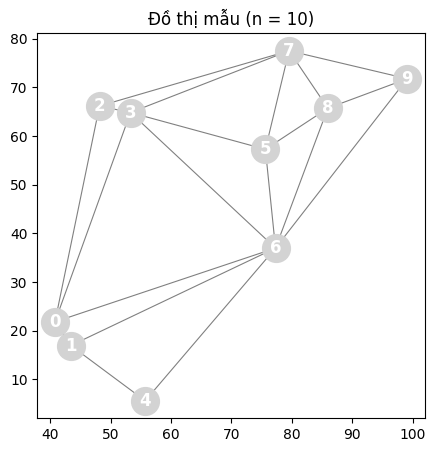

In [2]:
COLORS = ['red', 'blue', 'green', 'orange']   # 3 màu = 3 màu đầu, 4 màu = cả 4


def make_graph(n, seed=None):
    # Tạo n điểm ngẫu nhiên, sắp xếp theo x, tam giác phân Delaunay, trả về danh sách kề.
    rng = np.random.default_rng(seed)
    points = rng.random((n, 2)) * 100
    points = points[np.argsort(points[:, 0]), :]
    tri = Delaunay(points)

    indptr, indices = tri.vertex_neighbor_vertices
    neighbors = [np.sort(indices[indptr[k]:indptr[k + 1]]) for k in range(len(indptr) - 1)]
    return points, tri, neighbors


def make_csp_from_edges(num_vertices, edges, colors):
    # Dựng CSP theo đúng định dạng của notebook gốc (+ danh sách kề 'adj').
    variables = [str(v) for v in range(num_vertices)]
    domains = {v: list(colors) for v in variables}          # mỗi biến một list riêng
    constraints = [(str(i), str(j)) for (i, j) in edges]
    adj = {v: [] for v in variables}
    for a, b in constraints:
        adj[a].append(b)
        adj[b].append(a)
    return {'variables': variables, 'domains': domains,
            'constraints': constraints, 'adj': adj}


def make_csp(neighbors, colors):
    edges = [(i, int(j)) for i in range(len(neighbors)) for j in neighbors[i] if i < j]
    return make_csp_from_edges(len(neighbors), edges, colors)


def plot_coloring(points, tri, assignment=None, title=''):
    n = len(points)
    plt.figure(figsize=(5, 5))
    plt.triplot(points[:, 0], points[:, 1], tri.simplices, color='gray', linewidth=0.8)
    for i in range(n):
        c = assignment[str(i)] if assignment and str(i) in assignment else 'lightgray'
        plt.plot(points[i, 0], points[i, 1], 'o', color=c, markersize=20 if n <= 30 else 9)
        if n <= 30:
            plt.annotate(i, points[i, :], color='white', fontsize='large', weight='heavy',
                         horizontalalignment='center', verticalalignment='center')
    plt.title(title)
    plt.show()


# Ví dụ như notebook gốc: n = 10 điểm, 4 màu
points, tri, neighbors = make_graph(10, seed=1111)
csp = make_csp(neighbors, COLORS)
print("Số đỉnh:", len(csp['variables']), "| số cạnh (ràng buộc):", len(csp['constraints']))
plot_coloring(points, tri, title="Đồ thị mẫu (n = 10)")

## 2. Kiểm tra `complete` và `consistent`

`assignment` là dict `{biến: màu}`; `{}` là phép gán rỗng. Hai hàm đầu giữ nguyên như notebook của thầy. `consistent_var` là bản nhanh: chỉ kiểm tra các cạnh đi qua đỉnh vừa gán (các cạnh còn lại đã được kiểm tra ở bước trước).

In [3]:
def complete(assignment, csp):
    return all([v in assignment.keys() for v in csp['variables']])


def consistent(assignment, csp):
    for constr in csp['constraints']:
        if constr[0] in assignment.keys() and constr[1] in assignment.keys():
            if assignment[constr[0]] == assignment[constr[1]]:
                return False
    return True


def consistent_var(var, val, assignment, csp):
    # Gán var = val có xung đột với đỉnh kề đã được gán không?
    return all(assignment.get(nb) != val for nb in csp['adj'][var])


print("complete({}, csp)      =", complete({}, csp))
print("consistent({}, csp)    =", consistent({}, csp))
print("consistent({'0': 'red', '1': 'red'}) =", consistent({'0': 'red', '1': 'red'}, csp),
      "(chỉ đúng nếu 0 và 1 không kề nhau)")

complete({}, csp)      = False
consistent({}, csp)    = True
consistent({'0': 'red', '1': 'red'}) = False (chỉ đúng nếu 0 và 1 không kề nhau)


## 3. Chọn biến và chọn giá trị (điểm tích hợp với phần của Thắng)

`backtrack` nhận hai hàm làm tham số nên có thể thay heuristic mà không phải sửa thuật toán:

* `select_var(assignment, csp, domains)` → tên biến chưa gán kế tiếp (hoặc `None`).
* `order_values(var, assignment, csp, domains)` → list các giá trị thử theo thứ tự.

Trong đó `domains` là **miền hiện tại** (đã bị Forward Checking thu hẹp), không phải `csp['domains']`.

* `select_first` / `order_default` là cách chọn mặc định của notebook gốc (biến đầu tiên chưa gán, giá trị theo thứ tự miền).
* `select_mrv` / `order_lcv` bên dưới là **bản tạm tối thiểu** để notebook chạy trọn vẹn. **Thắng thay bằng bản của mình, giữ nguyên chữ ký hàm** (tên hàm, các tham số, giá trị trả về).

In [4]:
# ---------- Mặc định (như notebook gốc) ----------
def select_first(assignment, csp, domains):
    for v in csp['variables']:
        if v not in assignment:
            return v
    return None


def order_default(var, assignment, csp, domains):
    return list(domains[var])


# ---------- BẢN TẠM cho MRV / LCV: Thắng thay bằng bản của mình ----------
def legal_values(var, assignment, csp, domains):
    used = {assignment[nb] for nb in csp['adj'][var] if nb in assignment}
    return [c for c in domains[var] if c not in used]


def select_mrv(assignment, csp, domains):
    # Minimum-remaining-values; hòa thì chọn đỉnh có nhiều hàng xóm hơn (degree heuristic).
    unassigned = [v for v in csp['variables'] if v not in assignment]
    if not unassigned:
        return None
    return min(unassigned, key=lambda v: (len(legal_values(v, assignment, csp, domains)),
                                          -len(csp['adj'][v])))


def order_lcv(var, assignment, csp, domains):
    # Least-constraining-value: thử trước màu loại bỏ ít lựa chọn của các đỉnh kề chưa gán nhất.
    def ruled_out(val):
        return sum(1 for nb in csp['adj'][var] if nb not in assignment and val in domains[nb])
    return sorted(legal_values(var, assignment, csp, domains), key=ruled_out)

## 4. Backtracking Search + Forward Checking

### Mục tiêu
Backtracking thuần chỉ phát hiện ngõ cụt khi *đã gán nhầm* và quay lại sau đó, nên có thể lãng phí rất nhiều nút. Forward Checking (FC) phát hiện ngõ cụt sớm hơn: ngay sau khi gán màu cho một đỉnh, ta cập nhật miền của các đỉnh kề.

### Cách hoạt động
Sau khi gán `var = val`:

1. Với mỗi đỉnh kề `nb` **chưa được gán**, nếu `val` còn trong miền của `nb` thì xóa `val` khỏi miền đó (ghi nhớ `nb` đã bị xóa để hoàn tác).
2. Nếu có đỉnh kề nào **hết màu hợp lệ** (miền rỗng) thì FC báo thất bại và `backtrack` thử màu khác ngay, không đi sâu hơn.
3. Khi quay lui (hoặc FC thất bại), **trả lại** `val` vào miền của các đỉnh đã bị xóa, để nhánh sau thấy miền nguyên vẹn.

Biến `COUNT` đếm số nút của cây tìm kiếm (mỗi lần gọi `backtrack`) giống notebook gốc. Tham số `max_nodes` chặn các lần chạy quá lâu: khi vượt giới hạn, kết quả ghi là `limit` (chưa kết luận được), còn `unsat` nghĩa là đã duyệt hết cây và chứng minh không có nghiệm.

In [ ]:
COUNT = 0
VERBOSE = False


class NodeLimit(Exception):
    pass


def forward_check(var, val, assignment, domains, csp):
    # Xóa val khỏi miền các đỉnh kề chưa gán.
    # Trả về (ok, removed): ok = False nếu có miền rỗng; removed = các đỉnh đã bị xóa (để hoàn tác).
    removed = []
    for nb in csp['adj'][var]:
        if nb not in assignment and val in domains[nb]:
            domains[nb].remove(val)
            removed.append(nb)
            if not domains[nb]:
                return False, removed
    return True, removed


def backtrack(assignment, csp, domains, forward_checking, select_var, order_values, max_nodes):
    global COUNT
    COUNT += 1
    if max_nodes is not None and COUNT >= max_nodes:
        raise NodeLimit()

    if complete(assignment, csp):
        return assignment

    var = select_var(assignment, csp, domains)

    for val in order_values(var, assignment, csp, domains):
        if not consistent_var(var, val, assignment, csp):
            continue
        assignment[var] = val
        if VERBOSE: print(f"Checking: {assignment}")

        removed, ok = [], True
        if forward_checking:
            ok, removed = forward_check(var, val, assignment, domains, csp)

        if ok:
            result = backtrack(assignment, csp, domains, forward_checking,
                               select_var, order_values, max_nodes)
            if result is not None:
                return result

        for nb in removed:            # hoàn tác Forward Checking
            domains[nb].append(val)
        del assignment[var]

    if VERBOSE: print("Backtracking")
    return None


def solve_backtracking(csp, forward_checking=False, select_var=select_first,
                       order_values=order_default, max_nodes=None):
    # Chạy backtracking, trả về dict: assignment, status ('solved' / 'unsat' / 'limit'), nodes, time.
    global COUNT
    COUNT = 0
    domains = {v: list(d) for v, d in csp['domains'].items()}   # bản sao: không động vào csp gốc
    t0 = time.perf_counter()
    try:
        res = backtrack({}, csp, domains, forward_checking, select_var, order_values, max_nodes)
        status = 'solved' if res is not None else 'unsat'
    except NodeLimit:
        res, status = None, 'limit'
    return {'assignment': res, 'status': status, 'nodes': COUNT,
            'time': time.perf_counter() - t0}


def backtrack_search(csp, **kwargs):
    # Giao diện giống notebook gốc: in số nút đã duyệt, trả về assignment (None nếu thất bại).
    r = solve_backtracking(csp, **kwargs)
    print(f"Checked nodes: {r['nodes']}  ({r['status']})")
    return r['assignment']

## 5. Min-Conflicts (hill climbing cục bộ)

### Mục tiêu
Thay vì xây nghiệm từng bước, Min-Conflicts bắt đầu từ một phép gán **đầy đủ nhưng có thể sai** rồi sửa dần. Cách này không đảm bảo (không chứng minh được "vô nghiệm") nhưng thường rất nhanh khi có nghiệm.

### Cách hoạt động
1. **Khởi tạo:** gán ngẫu nhiên một màu cho mỗi đỉnh.
2. Lặp tối đa `max_steps` bước:
   * Nếu không còn cạnh nào có hai đầu cùng màu thì **dừng, tìm được nghiệm**.
   * Chọn ngẫu nhiên một đỉnh *đang vi phạm ràng buộc*.
   * Đổi đỉnh đó sang màu **tạo ra ít xung đột nhất** với các đỉnh kề (hòa thì chọn ngẫu nhiên giữa các màu hòa).
3. Nếu hết `max_steps` mà chưa có nghiệm thì **random restart**: khởi tạo lại ngẫu nhiên, tối đa `max_restarts` lần.

Đề bài yêu cầu báo cáo *uphill moves* và *random restarts*, nên hàm ghi lại:

* `steps`: tổng số lần đổi màu (cộng dồn qua các lần restart),
* `uphill`: số bước làm **giảm** số xung đột của đỉnh được chọn (bước leo dốc thật sự); các bước còn lại là đi ngang (bằng nhau) hoặc đi xuống,
* `restarts`: số lần khởi tạo lại.

Cài đặt dùng NumPy (mảng cạnh và mảng màu) để mỗi bước chạy nhanh, vì Min-Conflicts thường chạy rất nhiều bước.

In [6]:
def min_conflicts(csp, max_steps=1000, max_restarts=5, seed=None):
    # Min-Conflicts có random restart. Trả về dict: assignment, status, steps, uphill, restarts, time.
    rng = np.random.default_rng(seed)
    t0 = time.perf_counter()

    vars_ = csp['variables']
    idx = {v: i for i, v in enumerate(vars_)}
    n = len(vars_)
    colors = csp['domains'][vars_[0]]              # bài tô màu: mọi đỉnh cùng miền
    k = len(colors)
    nbrs = [np.array([idx[u] for u in csp['adj'][v]], dtype=int) for v in vars_]
    ea = np.array([idx[a] for a, b in csp['constraints']], dtype=int)
    eb = np.array([idx[b] for a, b in csp['constraints']], dtype=int)

    steps = uphill = 0
    for restart in range(max_restarts + 1):
        col = rng.integers(0, k, size=n)           # 1. khởi tạo ngẫu nhiên
        for step in range(max_steps + 1):
            bad = col[ea] == col[eb]               # các cạnh đang vi phạm
            if not bad.any():                      # 2a. không còn xung đột: xong
                return {'assignment': {vars_[i]: colors[col[i]] for i in range(n)},
                        'status': 'solved', 'steps': steps, 'uphill': uphill,
                        'restarts': restart, 'time': time.perf_counter() - t0}
            if step == max_steps:
                break
            conflicted = np.unique(np.concatenate([ea[bad], eb[bad]]))
            v = rng.choice(conflicted)             # 2b. chọn đỉnh vi phạm
            cnt = np.bincount(col[nbrs[v]], minlength=k)   # số xung đột của từng màu
            cur = cnt[col[v]]
            cand = cnt.copy()
            cand[col[v]] = n + 1                   # buộc phải đổi sang màu khác
            best = cand.min()
            col[v] = rng.choice(np.flatnonzero(cand == best))   # 2c. màu ít xung đột nhất
            steps += 1
            if best < cur:
                uphill += 1
    return {'assignment': None, 'status': 'limit', 'steps': steps, 'uphill': uphill,
            'restarts': max_restarts, 'time': time.perf_counter() - t0}

## 6. Kiểm thử tính đúng đắn

Trước khi chạy thí nghiệm lớn, kiểm tra các thuật toán trên các trường hợp đã biết đáp án:

* **Tam giác** ($K_3$) và **K4** (4 đỉnh đôi một kề nhau): K4 tô được bằng 4 màu nhưng **không** tô được bằng 3 màu. Backtracking và FC phải kết luận `unsat` ở ca 3 màu; Min-Conflicts không thể kết luận vô nghiệm nên phải trả về `limit`.
* Mọi nghiệm trả về phải qua kiểm tra đầy đủ `complete` và `consistent`.
* Forward Checking phải **không làm thay đổi** `csp['domains']` sau khi chạy.
* FC không được duyệt nhiều nút hơn Backtracking thuần (cùng thứ tự biến và giá trị).

In [7]:
def check_solution(res, csp):
    a = res['assignment']
    assert a is not None and complete(a, csp) and consistent(a, csp), "nghiệm sai!"

k3 = make_csp_from_edges(3, [(0, 1), (0, 2), (1, 2)], COLORS[:3])
k4_edges = [(i, j) for i in range(4) for j in range(i + 1, 4)]
k4_4 = make_csp_from_edges(4, k4_edges, COLORS[:4])
k4_3 = make_csp_from_edges(4, k4_edges, COLORS[:3])

for name, algo in [("BT", dict(forward_checking=False)), ("BT+FC", dict(forward_checking=True)),
                   ("BT+MRV+LCV+FC", dict(forward_checking=True, select_var=select_mrv, order_values=order_lcv))]:
    r = solve_backtracking(k3, **algo);   assert r['status'] == 'solved'; check_solution(r, k3)
    r = solve_backtracking(k4_4, **algo); assert r['status'] == 'solved'; check_solution(r, k4_4)
    r = solve_backtracking(k4_3, **algo); assert r['status'] == 'unsat'
    print(f"{name:15s}: K3(3 màu) = solved, K4(4 màu) = solved, K4(3 màu) = unsat   OK")

r = min_conflicts(k4_4, max_steps=200, max_restarts=5, seed=0); assert r['status'] == 'solved'; check_solution(r, k4_4)
r = min_conflicts(k4_3, max_steps=200, max_restarts=5, seed=0); assert r['status'] == 'limit'
print("Min-Conflicts  : K4(4 màu) = solved, K4(3 màu) = limit (không thể chứng minh vô nghiệm)   OK")

# FC không làm hỏng miền gốc và không duyệt nhiều nút hơn BT thuần
before = {v: list(d) for v, d in csp['domains'].items()}
r_bt = solve_backtracking(csp)
r_fc = solve_backtracking(csp, forward_checking=True)
assert csp['domains'] == before, "miền gốc bị thay đổi!"
assert r_fc['nodes'] <= r_bt['nodes']
check_solution(r_bt, csp); check_solution(r_fc, csp)
print(f"Đồ thị mẫu n = 10: BT = {r_bt['nodes']} nút, BT+FC = {r_fc['nodes']} nút   OK")

BT             : K3(3 màu) = solved, K4(4 màu) = solved, K4(3 màu) = unsat   OK
BT+FC          : K3(3 màu) = solved, K4(4 màu) = solved, K4(3 màu) = unsat   OK
BT+MRV+LCV+FC  : K3(3 màu) = solved, K4(4 màu) = solved, K4(3 màu) = unsat   OK
Min-Conflicts  : K4(4 màu) = solved, K4(3 màu) = limit (không thể chứng minh vô nghiệm)   OK
Đồ thị mẫu n = 10: BT = 11 nút, BT+FC = 11 nút   OK


### Chạy thử trên đồ thị mẫu (n = 10, 4 màu)

So sánh Backtracking thuần, Backtracking + Forward Checking và Min-Conflicts trên cùng một đồ thị; vẽ nghiệm của Forward Checking.

BT     : solved | nút duyệt =   11                  |   0.06 ms
BT+FC  : solved | nút duyệt =   11                  |   0.05 ms
MinConf: solved | bước =    3, uphill = 3, restart = 0 |   0.53 ms


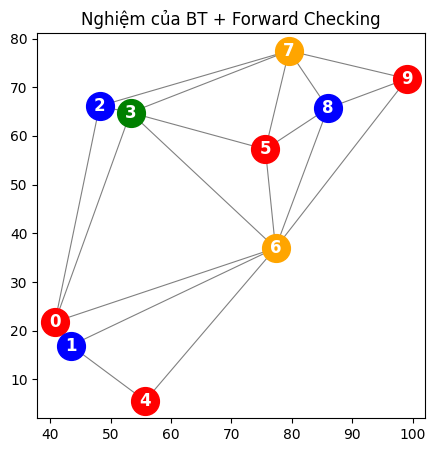

In [8]:
r_bt = solve_backtracking(csp)
r_fc = solve_backtracking(csp, forward_checking=True)
r_mc = min_conflicts(csp, max_steps=1000, max_restarts=5, seed=1)

print(f"BT     : {r_bt['status']:6s} | nút duyệt = {r_bt['nodes']:4d}                  | {r_bt['time']*1000:6.2f} ms")
print(f"BT+FC  : {r_fc['status']:6s} | nút duyệt = {r_fc['nodes']:4d}                  | {r_fc['time']*1000:6.2f} ms")
print(f"MinConf: {r_mc['status']:6s} | bước = {r_mc['steps']:4d}, uphill = {r_mc['uphill']}, restart = {r_mc['restarts']} | {r_mc['time']*1000:6.2f} ms")

plot_coloring(points, tri, r_fc['assignment'], title="Nghiệm của BT + Forward Checking")

## 7. Thí nghiệm

### Thiết lập
* Số đỉnh $n \in \{10, 20, 40, 80, 150\}$; mỗi cỡ **10 đồ thị ngẫu nhiên** (seed cố định); miền **3 màu** và **4 màu**. Mọi thuật toán chạy trên đúng cùng các đồ thị.
* Bốn thuật toán: `BT` (backtracking thuần), `BT+FC`, `BT+MRV+LCV+FC` (kết hợp với phần của Thắng), `MinConf` (Min-Conflicts).
* Backtracking giới hạn `max_nodes = 20000` nút. Một lần chạy chạm giới hạn được tính là **không tìm được nghiệm** (trạng thái `limit`). Nếu duyệt hết cây mà không có nghiệm thì là `unsat`.
* Min-Conflicts: `max_steps = 30·n` mỗi lần khởi tạo, tối đa 5 lần random restart.
* Chỉ số: **tỷ lệ tìm được nghiệm**, **số nút `COUNT` (backtracking) hoặc số bước (Min-Conflicts)**, **thời gian chạy**, số cạnh trung bình, và với Min-Conflicts thêm số bước uphill và số lần restart.

In [9]:
SIZES = [10, 20, 40, 80, 150]
COLOR_COUNTS = [3, 4]
N_INSTANCES = 10
MAX_NODES = 20000
MC_STEPS_PER_VERTEX = 30
MC_RESTARTS = 5

BT_VARIANTS = {
    'BT':            dict(forward_checking=False),
    'BT+FC':         dict(forward_checking=True),
    'BT+MRV+LCV+FC': dict(forward_checking=True, select_var=select_mrv, order_values=order_lcv),
}


def run_experiments():
    rows = []
    for n in SIZES:
        for inst in range(N_INSTANCES):
            seed = 1000 * n + inst
            _, _, neighbors = make_graph(n, seed)
            for k in COLOR_COUNTS:
                csp_i = make_csp(neighbors, COLORS[:k])
                edges = len(csp_i['constraints'])
                base = dict(n=n, instance=inst, colors=k, edges=edges)

                for name, kw in BT_VARIANTS.items():
                    r = solve_backtracking(csp_i, max_nodes=MAX_NODES, **kw)
                    if r['status'] == 'solved':
                        check_solution(r, csp_i)
                    rows.append({**base, 'algo': name, 'status': r['status'],
                                 'solved': r['status'] == 'solved', 'work': r['nodes'],
                                 'time': r['time'], 'uphill': np.nan, 'restarts': np.nan})

                r = min_conflicts(csp_i, max_steps=MC_STEPS_PER_VERTEX * n,
                                  max_restarts=MC_RESTARTS, seed=seed)
                if r['status'] == 'solved':
                    check_solution(r, csp_i)
                rows.append({**base, 'algo': 'MinConf', 'status': r['status'],
                             'solved': r['status'] == 'solved', 'work': r['steps'],
                             'time': r['time'], 'uphill': r['uphill'], 'restarts': r['restarts']})
    return pd.DataFrame(rows)


t_start = time.perf_counter()
df = run_experiments()
print(f"Xong {len(df)} lượt chạy trong {time.perf_counter() - t_start:.1f} giây.")

Xong 400 lượt chạy trong 18.1 giây.


### Số cạnh trung bình theo n

Đồ thị tam giác phân của $n$ điểm có tối đa $3n - 6$ cạnh (tối đa khi bao lồi của tập điểm là tam giác); với điểm ngẫu nhiên số cạnh thực tế thấp hơn một chút vì các điểm trên bao lồi làm mất cạnh.

In [10]:
algo_order = ['BT', 'BT+FC', 'BT+MRV+LCV+FC', 'MinConf']

edge_tab = (df.drop_duplicates(['n', 'instance']).groupby('n')['edges']
              .agg(['mean', 'min', 'max']).round(1))
edge_tab.columns = ['Số cạnh TB', 'Min', 'Max']
edge_tab['3n - 6'] = [3 * n - 6 for n in edge_tab.index]
edge_tab['Cạnh TB / n'] = (edge_tab['Số cạnh TB'] / edge_tab.index).round(2)
edge_tab.index.name = 'n'
display(edge_tab)

,Số cạnh TB,Min,Max,3n - 6,Cạnh TB / n
n,,,,,
10,21.3,20,22,24,2.13
20,49.4,48,51,54,2.47
40,108.0,105,112,114,2.70
80,226.5,224,228,234,2.83
150,434.3,431,437,444,2.90


### Bảng kết quả

**Tỷ lệ tìm được nghiệm (%)** trên 10 đồ thị mỗi cỡ:

In [11]:
def pivot(values, aggfunc='mean', scale=1.0, digits=1):
    t = df.pivot_table(index=['colors', 'n'], columns='algo', values=values, aggfunc=aggfunc)
    return (t[algo_order] * scale).round(digits)

success = pivot('solved', scale=100, digits=0)
success.index.names = ['Số màu', 'n']
display(success)

algo           BT  BT+FC  BT+MRV+LCV+FC  MinConf
Số màu n                                        
3      10    20.0   20.0           20.0     20.0
       20     0.0    0.0            0.0      0.0
       40     0.0    0.0            0.0      0.0
       80     0.0    0.0            0.0      0.0
       150    0.0    0.0            0.0      0.0
4      10   100.0  100.0          100.0    100.0
       20   100.0  100.0          100.0    100.0
       40   100.0  100.0          100.0    100.0
       80   100.0  100.0          100.0    100.0
       150   90.0  100.0           80.0    100.0

**Số nút `COUNT` (backtracking) / số bước (Min-Conflicts)**, trung bình trên *tất cả* lượt chạy. Lượt chạm giới hạn tính đúng bằng `max_nodes` nên giá trị trung bình thực tế còn cao hơn nếu không có giới hạn.

In [12]:
work = pivot('work', digits=0)
work.index.names = ['Số màu', 'n']
display(work)

algo            BT   BT+FC  BT+MRV+LCV+FC  MinConf
Số màu n                                          
3      10     31.0    21.0           19.0   1445.0
       20    104.0    51.0           33.0   3600.0
       40    164.0    68.0           35.0   7200.0
       80    321.0    80.0           42.0  14400.0
       150   188.0    84.0           59.0  27000.0
4      10     11.0    11.0           11.0      8.0
       20     26.0    23.0           22.0     29.0
       40    274.0    50.0           47.0    145.0
       80    820.0   182.0          125.0    404.0
       150  8461.0  1893.0         4174.0    880.0

**Thời gian chạy trung bình (ms):**

In [13]:
runtime = pivot('time', scale=1000, digits=2)
runtime.index.names = ['Số màu', 'n']
display(runtime)

algo           BT  BT+FC  BT+MRV+LCV+FC  MinConf
Số màu n                                        
3      10    0.11   0.06           0.17    30.24
       20    0.34   0.16           0.46    82.65
       40    0.79   0.31           0.83   169.85
       80    1.91   0.45           2.09   365.86
       150   1.60   0.71           4.89   785.13
4      10    0.04   0.03           0.09     0.23
       20    0.10   0.13           0.24     0.73
       40    1.38   0.20           0.77     3.50
       80    6.18   1.17           4.42     9.44
       150  91.29  19.51         185.67    24.44

**Chi tiết các lượt chạy** (`solved` = tìm được nghiệm; `unsat` = đã chứng minh vô nghiệm; `limit` = chạm giới hạn nút / bước, chưa kết luận):

In [14]:
status_tab = (df.groupby(['colors', 'n', 'algo'])['status'].value_counts()
                .unstack(fill_value=0)
                .reindex(columns=['solved', 'unsat', 'limit'], fill_value=0))
status_tab = status_tab.reindex(algo_order, level='algo')
status_tab = status_tab.sort_index(level=['colors', 'n'], sort_remaining=False)
status_tab.index.names = ['Số màu', 'n', 'Thuật toán']
display(status_tab)

status                    solved  unsat  limit
Số màu n   Thuật toán                         
3      10  BT                  2      8      0
           BT+FC               2      8      0
           BT+MRV+LCV+FC       2      8      0
           MinConf             2      0      8
       20  BT                  0     10      0
           BT+FC               0     10      0
           BT+MRV+LCV+FC       0     10      0
           MinConf             0      0     10
       40  BT                  0     10      0
           BT+FC               0     10      0
           BT+MRV+LCV+FC       0     10      0
           MinConf             0      0     10
       80  BT                  0     10      0
           BT+FC               0     10      0
           BT+MRV+LCV+FC       0     10      0
           MinConf             0      0     10
       150 BT                  0     10      0
           BT+FC               0     10      0
           BT+MRV+LCV+FC       0     10      0
           MinConf             0      0     10
4      10  BT                 10      0      0
           BT+FC              10      0      0
           BT+MRV+LCV+FC      10      0      0
           MinConf            10      0      0
       20  BT                 10      0      0
           BT+FC              10      0      0
           BT+MRV+LCV+FC      10      0      0
           MinConf            10      0      0
       40  BT                 10      0      0
           BT+FC              10      0      0
           BT+MRV+LCV+FC      10      0      0
           MinConf            10      0      0
       80  BT                 10      0      0
           BT+FC              10      0      0
           BT+MRV+LCV+FC      10      0      0
           MinConf            10      0      0
       150 BT                  9      0      1
           BT+FC              10      0      0
           BT+MRV+LCV+FC       8      0      2
           MinConf            10      0      0

**Min-Conflicts: số bước uphill và số lần random restart** (trung bình trên các lượt chạy; tính cả lượt không thành công):

In [15]:
mc = df[df['algo'] == 'MinConf']
mc_tab = mc.groupby(['colors', 'n']).agg(
    thanh_cong_pct=('solved', lambda s: round(100 * s.mean())),
    buoc_TB=('work', 'mean'),
    uphill_TB=('uphill', 'mean'),
    restart_TB=('restarts', 'mean'),
).round(1)
mc_tab.columns = ['Thành công (%)', 'Số bước TB', 'Uphill TB', 'Restart TB']
mc_tab.index.names = ['Số màu', 'n']
display(mc_tab)

Thành công (%)  Số bước TB  Uphill TB  Restart TB
Số màu n                                                     
3      10               20      1445.3      318.4         4.0
       20                0      3600.0      974.4         5.0
       40                0      7200.0     2094.0         5.0
       80                0     14400.0     4382.3         5.0
       150               0     27000.0     8397.4         5.0
4      10              100         8.4        4.0         0.0
       20              100        28.7       10.0         0.0
       40              100       145.1       35.6         0.0
       80              100       403.5       75.3         0.0
       150             100       879.7      172.1         0.0

### Biểu đồ

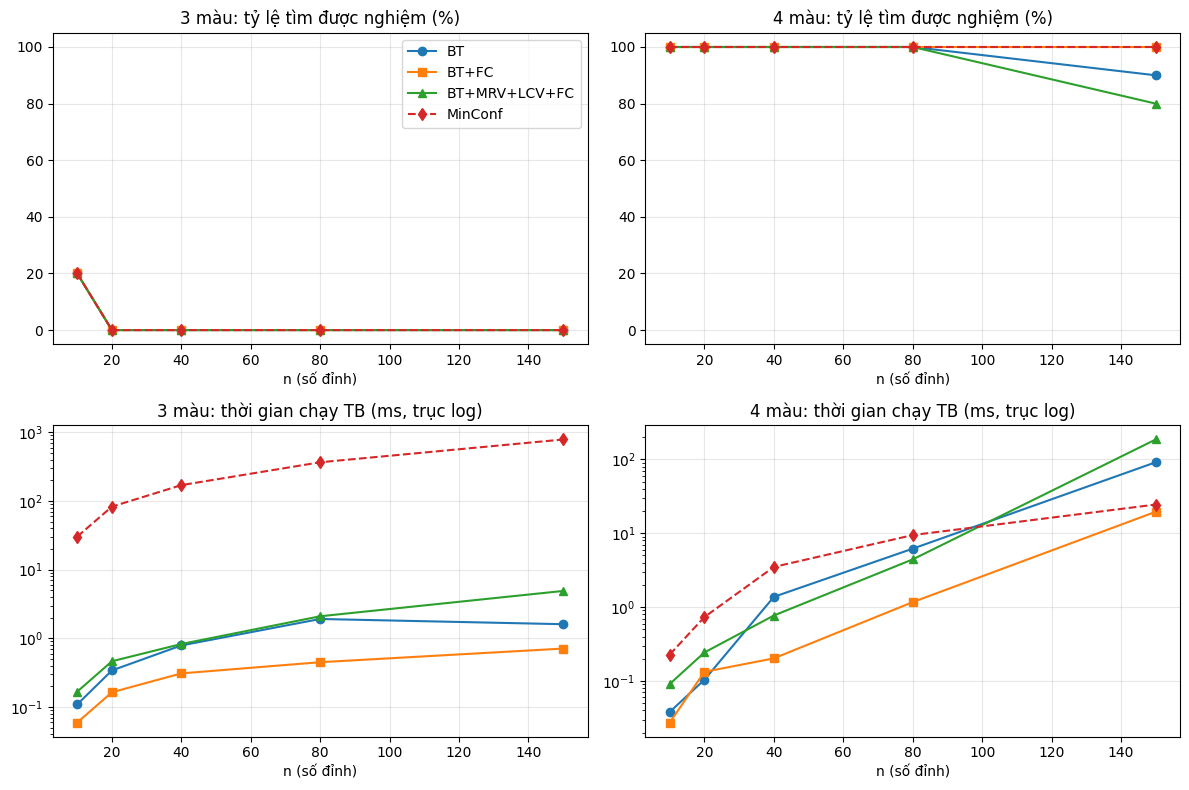

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
styles = {'BT': 'o-', 'BT+FC': 's-', 'BT+MRV+LCV+FC': '^-', 'MinConf': 'd--'}

for col_i, k in enumerate(COLOR_COUNTS):
    sub = df[df['colors'] == k]
    for algo in algo_order:
        g = sub[sub['algo'] == algo].groupby('n')
        axes[0, col_i].plot(g['solved'].mean().index, 100 * g['solved'].mean(), styles[algo], label=algo)
        axes[1, col_i].plot(g['time'].mean().index, 1000 * g['time'].mean(), styles[algo], label=algo)
    axes[0, col_i].set_title(f"{k} màu: tỷ lệ tìm được nghiệm (%)")
    axes[0, col_i].set_ylim(-5, 105)
    axes[1, col_i].set_title(f"{k} màu: thời gian chạy TB (ms, trục log)")
    axes[1, col_i].set_yscale('log')
    for ax in axes[:, col_i]:
        ax.set_xlabel('n (số đỉnh)')
        ax.grid(alpha=0.3)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## 8. Nhận xét

> Các con số bên dưới lấy từ lần chạy với seed cố định ở mục 7 (số nút và số bước tái lập được, thời gian thì tùy máy). `select_mrv` và `order_lcv` hiện là bản tạm; **sau khi Thắng thay bản chính thức, hãy chạy lại và cập nhật các nhận xét về cột `BT+MRV+LCV+FC`.**

**Số cạnh.** Số cạnh trung bình tăng gần tuyến tính theo $n$ và luôn nhỏ hơn $3n - 6$: khoảng $2{,}1n$ cạnh khi $n = 10$ và $2{,}9n$ khi $n = 150$ (434 cạnh), tiến dần tới $3n$ khi $n$ lớn vì tỷ lệ điểm nằm trên bao lồi giảm.

**3 màu: gần như luôn vô nghiệm.** Chỉ có 2 trên 50 đồ thị là tô được bằng 3 màu (cả hai đều có $n = 10$); từ $n = 20$ trở lên không đồ thị nào tô được. Mỗi tam giác của phép tam giác phân buộc ba đỉnh dùng đủ cả ba màu, nên ràng buộc rất chặt và dễ mâu thuẫn khi đồ thị lớn. Hệ quả:

* Ba biến thể backtracking đều **chứng minh được vô nghiệm** (`unsat`) với số nút rất nhỏ; Forward Checking và MRV/LCV giảm số nút rõ rệt. Ví dụ $n = 80$: 321 nút (BT), 80 nút (BT+FC), 42 nút (BT+MRV+LCV+FC). Số nút không tăng đơn điệu theo $n$ vì lỗi thường bị phát hiện ở một vùng cục bộ của đồ thị.
* **Min-Conflicts không bao giờ kết luận được vô nghiệm**: nó dùng hết toàn bộ ngân sách bước và restart (`limit`), nên là phương pháp *đắt nhất* ở các ca này (hàng nghìn ms ở $n = 150$). Số bước uphill vẫn lớn nhưng không dẫn tới nghiệm vì không có nghiệm.

**4 màu: Forward Checking và Min-Conflicts tốt hơn rõ.** Theo định lý bốn màu, đồ thị phẳng luôn tô được bằng 4 màu và có rất nhiều nghiệm.

* Backtracking thuần tăng nhanh theo $n$: trung bình 11 nút ($n = 10$) lên 8461 nút ($n = 150$), và 1 trên 10 đồ thị cỡ 150 chạm giới hạn 20000 nút (tỷ lệ thành công 90%).
* **Forward Checking** giảm số nút khoảng 4–5 lần ở $n = 150$ (1893 so với 8461), thời gian từ khoảng 168 ms xuống khoảng 37 ms, và giải được cả 10/10 đồ thị. Nó phát hiện sớm khi một đỉnh kề hết màu, thay vì chỉ phát hiện khi tới lượt đỉnh đó.
* **Min-Conflicts** giải 10/10 đồ thị ở mọi cỡ, **không cần random restart lần nào** (restart TB = 0), với khoảng 880 bước ở $n = 150$, trong đó khoảng 20% là bước uphill thật sự. Số bước tăng chậm (xấp xỉ tuyến tính theo $n$), trong khi số nút của backtracking tăng nhanh hơn. Lưu ý một "bước" của Min-Conflicts và một "nút" của backtracking không cùng đơn vị chi phí; khi $n$ nhỏ, Min-Conflicts chậm hơn về thời gian do chi phí NumPy cố định cho mỗi bước.
* **MRV + LCV (bản tạm):** ở $n = 80$ giảm số nút so với BT+FC (125 so với 182) nhưng ở $n = 150$ có 2/10 lần chạm giới hạn nên trung bình lại cao hơn (4174 so với 1893). Đây là hiện tượng đuôi nặng của backtracking: vài đồ thị rơi vào nhánh xấu. Mỗi nút của heuristic này cũng đắt hơn (phải đếm giá trị hợp lệ của mọi đỉnh chưa gán), nên thời gian chạy cao hơn. Cần đánh giá lại bằng bản của Thắng.

**Kết luận ngắn.** Khi bài toán có nghiệm và còn "thoáng" (4 màu), Min-Conflicts và Backtracking + Forward Checking đều giải được cỡ vài trăm đỉnh; Forward Checking luôn tốt hơn backtracking thuần. Khi bài toán chặt hoặc vô nghiệm (3 màu), chỉ phương pháp có hệ thống (backtracking) mới kết luận được, còn Min-Conflicts chỉ báo "chưa tìm thấy".

## 9. Discussion câu 3

**Đề:** *Vì sao tô màu bằng 3 màu có thể thất bại dù dùng thuật toán đúng? Làm sao phân biệt hết giới hạn tính toán và chứng minh vô nghiệm?*

### a) Vì sao 3 màu có thể thất bại dù thuật toán đúng

1. **"Thuật toán đúng" không có nghĩa là "luôn tìm được nghiệm".** Thuật toán đúng nghĩa là mọi nghiệm nó trả về đều hợp lệ (đã kiểm tra bằng `check_solution`) và, nếu nó *đầy đủ* (như backtracking), nó tìm được nghiệm *khi có nghiệm*. Nếu bài toán không có nghiệm thì "không tìm được" chính là kết quả đúng.
2. **Bản thân đồ thị thường không tô được bằng 3 màu.** Đồ thị phẳng luôn tô được bằng 4 màu (định lý bốn màu) nhưng 3 màu thì không đủ: K4 là đồ thị phẳng và cần 4 màu (xem mục 6). Trong thí nghiệm, chỉ 2 trên 50 đồ thị Delaunay tô được bằng 3 màu.
3. **Có một lý do cấu trúc rất cụ thể.** Trong tam giác phân, các hàng xóm của một đỉnh *bên trong* (không nằm trên bao lồi) tạo thành một chu trình khép kín. Nếu đỉnh đó có **bậc lẻ**, chu trình lẻ này cần 3 màu và đỉnh trung tâm kề với tất cả nên cần một màu thứ 4, do đó **không thể tô bằng 3 màu**. Khi $n$ tăng, gần như chắc chắn có ít nhất một đỉnh trong bậc lẻ, nên khả năng tô được bằng 3 màu giảm rất nhanh.
4. **Bài toán quyết định "có tô được bằng 3 màu không" là NP-đầy đủ**, kể cả với đồ thị phẳng. Không có thuật toán nhanh cho mọi trường hợp, nên với đồ thị lớn một tìm kiếm đúng vẫn có thể phải duyệt rất nhiều nút.
5. **Với thuật toán không đầy đủ (Min-Conflicts), thất bại còn có thể do kẹt ở cực tiểu cục bộ hoặc hết số bước**, kể cả khi *có* nghiệm. Vì vậy thất bại của nó không cho biết gì về việc nghiệm có tồn tại hay không.

### b) Phân biệt "hết giới hạn tính toán" và "chứng minh vô nghiệm"

Điều quyết định là **thuật toán có đầy đủ không và có bị cắt giữa chừng không**. Cài đặt ở mục 4 và 5 tách rõ ba trạng thái:

| Trạng thái | Ý nghĩa | Cơ sở |
|---|---|---|
| `solved` | Có nghiệm | Nghiệm kiểm tra lại được trong $O(E)$ (`check_solution`). |
| `unsat` (backtracking) | **Đã chứng minh vô nghiệm** | Cây tìm kiếm được duyệt cạn và *không* chạm `max_nodes`. Forward Checking chỉ loại các màu không thể thuộc nghiệm nào, nên không bỏ sót nghiệm. |
| `limit` (backtracking) | **Chưa kết luận được** | `NodeLimit` bị ném ra giữa chừng, cây chưa duyệt hết: có thể có nghiệm, có thể không. |
| `limit` (Min-Conflicts) | **Chưa kết luận được** | Hết `max_steps` và `max_restarts`. Chỉ là bằng chứng yếu, không phải chứng minh. |

Kết luận "vô nghiệm" chỉ đúng khi thỏa **cả hai** điều kiện: (i) thuật toán đầy đủ, (ii) tìm kiếm kết thúc tự nhiên chứ không bị giới hạn nút hoặc thời gian cắt. Hai nhận định sau được kiểm chứng ngay bằng dữ liệu của thí nghiệm.

**Bằng chứng 1: `limit` không có nghĩa là vô nghiệm.** Ở bài 4 màu, vài lượt backtracking chạm giới hạn, nhưng các đồ thị đó chắc chắn có nghiệm (định lý bốn màu) và thuật toán khác đã giải được: